<a href="https://colab.research.google.com/github/jalmendral/BA305-A1-TeamA2/blob/main/Regression%20Tree%20%26%20Random%20Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Can ingredients predict a recipe's rating?
Kenny — regression tree and random forest

Run the cells in order in Google Colab. This notebook replaces the earlier setup cells so all splits and cleaning stay consistent. It loads an uploaded `recipes_clean.csv` when available; otherwise it uses your GitHub URL.

**Primary metric: RMSE**, in rating points. Large misses receive more weight than small misses. The matching no-input baseline predicts the training mean. MAE and R² add context; neither replaces RMSE for model selection.

Only ingredient text is used to predict ratings. Review counts and other metadata are used for diagnosis only. Models predict observed average ratings, not intrinsic recipe quality or causal effects of ingredients.

The code has been syntax-checked, but training was not executed in the authoring environment. All scores and conclusions must come from your Colab run. The workflow follows the assignment text you supplied; the linked course repository could not be retrieved.

In [1]:
# 1. Import the tools used throughout the notebook.
# These packages are normally preinstalled in Google Colab.
import re
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import balanced_accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
N_JOBS = 2  # Limit parallel fits to avoid overwhelming Colab's memory.
sns.set_theme(style="whitegrid")
print("scikit-learn version:", sklearn.__version__)


scikit-learn version: 1.6.1


In [2]:
# 2. Load the data and inspect columns before modeling.
url = "https://raw.githubusercontent.com/jalmendral/BA305-A1-TeamA2/main/Data/processed/recipes_clean.csv"
local_file = Path("recipes_clean.csv")
df = pd.read_csv(local_file if local_file.exists() else url)
print("Rows and columns:", df.shape)
display(df.head())
display(pd.DataFrame({"data_type": df.dtypes,
                      "missing_values": df.isna().sum(),
                      "unique_values": df.nunique()}))
assert {"ingredients", "avg_rating"}.issubset(df.columns)


Rows and columns: (15589, 23)


,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,...,cook_time,total_time,servings,country,has_cuisine,year,nutrition_flag,time_flag,rating_missing,nutrition_missing
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,...,35.0,55.0,16.0,NaN,False,2020,False,False,False,False
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,...,5.0,495.0,8.0,NaN,False,2022,False,False,False,False
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,...,75.0,85.0,4.0,NaN,False,2018,False,False,False,False
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,...,40.0,60.0,8.0,NaN,False,2025,False,False,False,False
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,...,95.0,125.0,8.0,NaN,False,2024,False,False,False,False


,data_type,missing_values,unique_values
name,object,0,15562
url,object,0,15589
author,object,0,8982
date_published,object,0,1580
ingredients,object,10,15573
calories,float64,238,1104
fat,float64,400,121
carbs,float64,244,173
protein,float64,289,99
avg_rating,float64,1030,31


In [3]:
# 3. Clean the target and remove unusable observations.
# This study assumes the site's observed rating scale is 1 to 5.
# Invalid/missing ratings are excluded, never replaced with an invented rating.
model_df = df.copy()
model_df["avg_rating"] = pd.to_numeric(model_df["avg_rating"], errors="coerce")
valid = (model_df["ingredients"].notna()
         & model_df["ingredients"].fillna("").astype(str).str.strip().ne("")
         & model_df["avg_rating"].between(1, 5))
print("Excluded for missing/invalid text or rating:", int((~valid).sum()))
model_df = model_df.loc[valid].copy()
model_df["ingredients"] = model_df["ingredients"].astype(str)

# Prevent the same recipe URL from appearing in different splits.
# Keep the first record without looking at which rating is most favorable.
if "url" in model_df:
    nonblank_url = model_df["url"].notna() & model_df["url"].fillna("").str.strip().ne("")
    duplicate_url = nonblank_url & model_df["url"].duplicated()
    print("Repeated recipe URLs removed:", int(duplicate_url.sum()))
    model_df = model_df.loc[~duplicate_url].copy()

# Remove exact repeated ingredient texts to reduce duplicate leakage.
# This changes the population to distinct ingredient texts; near-duplicates may remain.
ingredient_key = model_df["ingredients"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
print("Repeated ingredient texts removed:", int(ingredient_key.duplicated().sum()))
model_df = model_df.loc[~ingredient_key.duplicated()].copy().reset_index(drop=True)
model_df["total_ratings"] = pd.to_numeric(model_df.get("total_ratings", np.nan), errors="coerce")
assert len(model_df) >= 100, "Too few usable recipes for the planned workflow."
X = model_df["ingredients"]
y = model_df["avg_rating"]
print("Recipes available:", len(model_df))
print("Example ingredients:", X.iloc[0])


Excluded for missing/invalid text or rating: 1030
Repeated recipe URLs removed: 0
Repeated ingredient texts removed: 4
Recipes available: 14555
Example ingredients: ⅓ cup margarine, softened, ⅔ cup white sugar, ½ cup packed brown sugar, 2  eggs, 1 cup peanut butter, ½ teaspoon vanilla extract, 2 tablespoons water, ¾ cup whole wheat flour, ¼ cup all-purpose flour, ¼ teaspoon salt, 1 teaspoon baking powder, ¼ teaspoon baking soda


In [4]:
# 4. Keep the original 80/20 train/test split, then reserve part of training
# for choosing a business threshold and reviewing errors before final testing.
# Overall: 64% fitting, 16% validation, 20% final test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED)
assert set(X_fit.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
print("Fit:", len(X_fit), "Validation:", len(X_val), "Test:", len(X_test))

# All regression searches and the dummy use identical cross-validation folds.
cv = list(KFold(n_splits=3, shuffle=True, random_state=SEED).split(X_fit))


Fit: 9315 Validation: 2329 Test: 2911


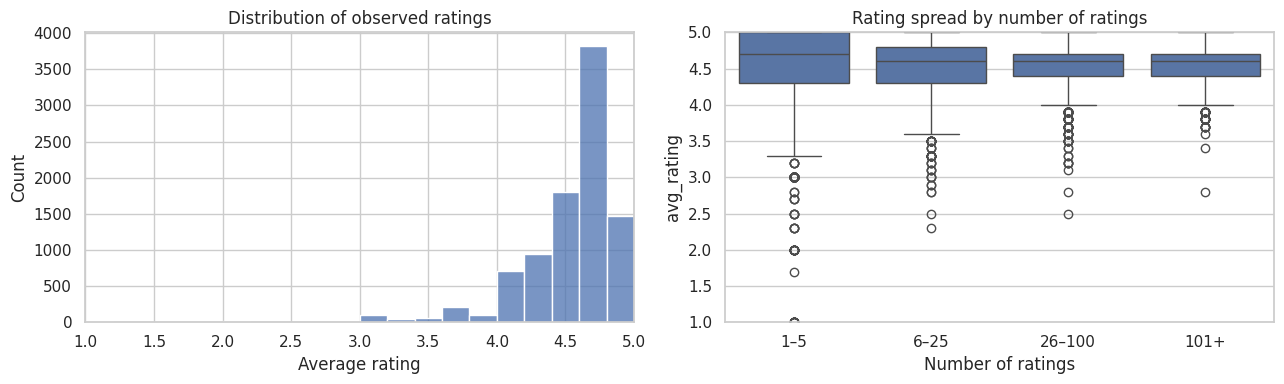

,avg_rating
count,9315.000000
mean,4.521267
std,0.413317
min,1.000000
25%,4.400000
50%,4.600000
75%,4.800000
max,5.000000


,count,mean,median,std
review_group,,,,
1–5,2539,4.514533,4.7,0.627400
6–25,2157,4.509040,4.6,0.368604
26–100,2244,4.507620,4.6,0.285135
101+,2375,4.552463,4.6,0.218773


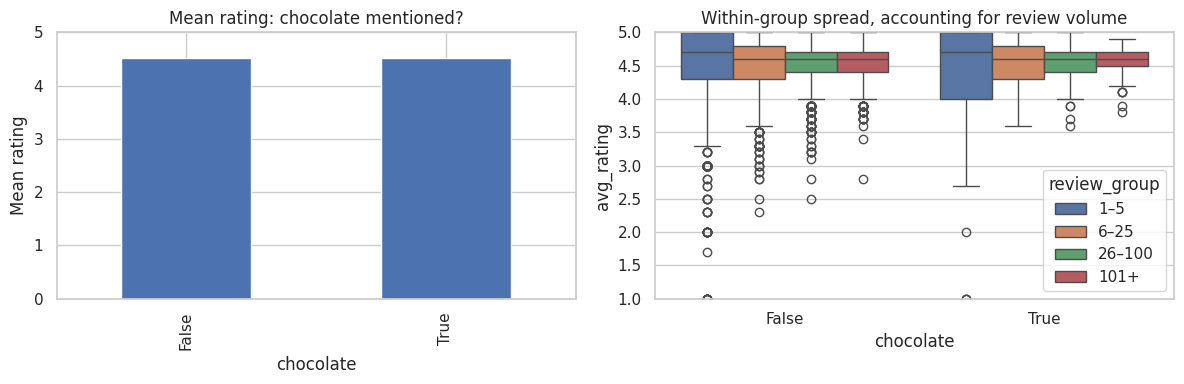

In [5]:
# 5. Start with charts of FITTING data only, leaving final test outcomes unseen.
eda = model_df.loc[X_fit.index].copy()
eda["review_group"] = pd.cut(eda["total_ratings"], [0, 5, 25, 100, np.inf],
                            labels=["1–5", "6–25", "26–100", "101+"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(eda["avg_rating"], bins=np.linspace(1, 5, 21), ax=axes[0])
axes[0].set(title="Distribution of observed ratings", xlabel="Average rating", xlim=(1, 5))
sns.boxplot(data=eda, x="review_group", y="avg_rating", ax=axes[1])
axes[1].set(title="Rating spread by number of ratings", xlabel="Number of ratings", ylim=(1, 5))
plt.tight_layout()
plt.show()
display(eda["avg_rating"].describe())
display(eda.groupby("review_group", observed=True)["avg_rating"].agg(["count", "mean", "median", "std"]))

# Compare means with distributions, and check review count as a third variable.
# A chocolate/non-chocolate difference is descriptive, not causal evidence.
eda["chocolate"] = eda["ingredients"].str.contains(r"\bchocolate\b", case=False, regex=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
eda.groupby("chocolate")["avg_rating"].mean().plot.bar(ax=axes[0])
axes[0].set(title="Mean rating: chocolate mentioned?", ylim=(0, 5), ylabel="Mean rating")
sns.boxplot(data=eda, x="chocolate", y="avg_rating", hue="review_group", ax=axes[1])
axes[1].set(title="Within-group spread, accounting for review volume", ylim=(1, 5))
plt.tight_layout()
plt.show()
# If the boxes overlap substantially, a small difference in means is weak evidence.


In [6]:
# 6. Turn ingredient text into numerical word/phrase presence features.
# Quantities and preparation notes are mixed into the text. Remove common
# measurement/preparation words, but keep meaningful words such as salt/sugar.
# This is a text representation, not a perfect standardized ingredient parser.
STOP_WORDS = sorted(set("cup cups tablespoon tablespoons teaspoon teaspoons ounce ounces pound pounds gram grams kilogram kilograms package packages can cans pinch taste needed optional chopped diced minced sliced divided softened fresh freshly large small medium and or of to for with as such into the a an".split()))

def make_vectorizer():
    return CountVectorizer(binary=True, lowercase=True, stop_words=STOP_WORDS,
                           token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
                           ngram_range=(1, 2), min_df=5, max_features=2000)

def make_pipeline(model):
    # Keeping the vectorizer INSIDE the pipeline means each CV training fold
    # learns its own vocabulary without seeing the validation fold.
    return Pipeline([("ingredients", make_vectorizer()), ("model", model)])

# Word pairs preserve some phrases, but may also cross ingredient boundaries.
# Standardizing ingredient names is a sensible future improvement.


In [7]:
# 7. Fit the no-input regression baseline.
# The mean is the constant prediction that minimizes squared error.
# RMSE is the square root of MSE, expressed in the original rating units.
def rmse(actual, predicted):
    return float(np.sqrt(mean_squared_error(actual, predicted)))

dummy = DummyRegressor(strategy="mean")
dummy_X = np.zeros((len(X_fit), 1))
dummy.fit(dummy_X, y_fit)
dummy_cv = -cross_val_score(dummy, dummy_X, y_fit, cv=cv,
                            scoring="neg_root_mean_squared_error")
print("Training mean prediction:", float(y_fit.mean()))
print("Baseline mean CV RMSE:", float(dummy_cv.mean()))


Training mean prediction: 4.521266774020396
Baseline mean CV RMSE: 0.41310575343923883


In [10]:
# 8. Tune two hyperparameters for BOTH methods using 3-fold grid search.
# max_depth: the number of levels a tree may grow; None allows unlimited depth.
# min_samples_leaf: minimum recipes in a leaf; larger values smooth predictions.
# Each initial grid has 6 depth values x 5 leaf sizes = 30 combinations.
# Each combination is tested on the SAME three CV folds.
# The forest averages 120 trees; that is a fixed compute choice, not a tuned value.
INITIAL_GRID = {"model__max_depth": [1, 3, 6, 12, 24, None],
                "model__min_samples_leaf": [1, 5, 15, 40, 100]}

def tune(model, X_data, y_data, folds, scoring):
    grid = {key: list(values) for key, values in INITIAL_GRID.items()}
    # Large leaf sizes may eventually make all trees constant.
    # Beyond half of the smallest CV training fold, no split is possible.
    leaf_limit = min(len(train) for train, valid in folds) // 2 + 1
    history = []
    while True:
        start = time.time()
        search = GridSearchCV(make_pipeline(clone(model)), grid, scoring=scoring,
                              cv=folds, n_jobs=N_JOBS, return_train_score=True,
                              error_score="raise", refit=True, verbose=2)
        search.fit(X_data, y_data)
        history.append(search)
        print(type(model).__name__, search.best_params_,
              "CV score:", round(search.best_score_, 4),
              "minutes:", round((time.time()-start)/60, 1))
        best_leaf = search.best_params_["model__min_samples_leaf"]
        # Widen the upper edge when it wins. A leaf size of 1 and depth of 1
        # are natural lower bounds; depth=None already covers unbounded trees.
        if best_leaf == max(grid["model__min_samples_leaf"]) and best_leaf < leaf_limit:
            new_leaf = min(best_leaf * 3, leaf_limit)
            grid["model__min_samples_leaf"].append(new_leaf)
            print("Expanding leaf-size range to", new_leaf)
        else:
            return search, history

tree_search, tree_history = tune(DecisionTreeRegressor(random_state=SEED),
    X_fit, y_fit, cv, "neg_root_mean_squared_error")
forest_search, forest_history = tune(RandomForestRegressor(
    n_estimators=50, max_features=0.5, n_jobs=1, random_state=SEED),
    X_fit, y_fit, cv, "neg_root_mean_squared_error")
searches = {"Regression tree": tree_search, "Random forest": forest_search}


Fitting 3 folds for each of 30 candidates, totalling 90 fits
DecisionTreeRegressor {'model__max_depth': 3, 'model__min_samples_leaf': 100} CV score: -0.411 minutes: 1.8
Expanding leaf-size range to 300
Fitting 3 folds for each of 36 candidates, totalling 108 fits
DecisionTreeRegressor {'model__max_depth': 6, 'model__min_samples_leaf': 300} CV score: -0.4107 minutes: 2.1
Expanding leaf-size range to 900
Fitting 3 folds for each of 42 candidates, totalling 126 fits
DecisionTreeRegressor {'model__max_depth': 6, 'model__min_samples_leaf': 300} CV score: -0.4107 minutes: 2.3
Fitting 3 folds for each of 30 candidates, totalling 90 fits
RandomForestRegressor {'model__max_depth': None, 'model__min_samples_leaf': 15} CV score: -0.4065 minutes: 6.6


,Train RMSE,CV RMSE,CV fold SD,CV minus train
Model,,,,
Mean baseline,0.4133,0.4131,0.0162,-0.0002
Regression tree,0.4087,0.4107,0.0145,0.0020
Random forest,0.3728,0.4065,0.0151,0.0337


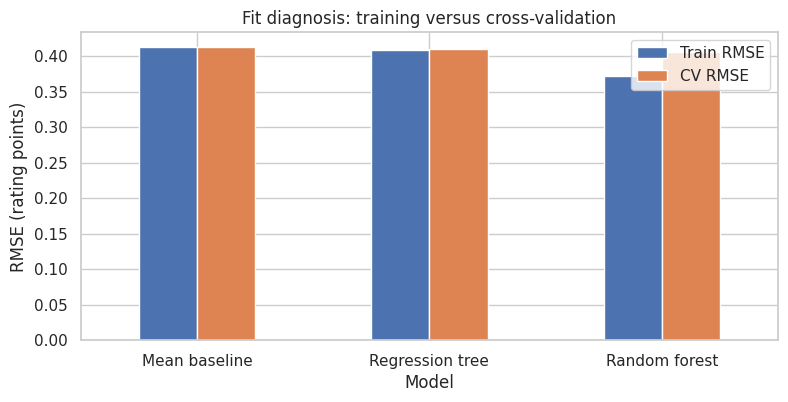

Regression method selected by CV: Random forest
Relative CV RMSE improvement over baseline: 1.6%
A small gain is a valid finding; do not describe it as strong prediction.


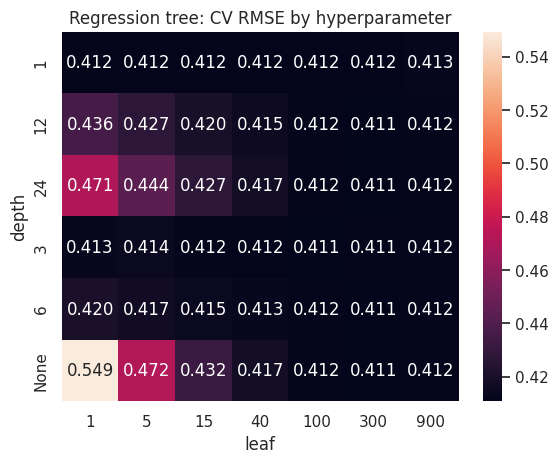

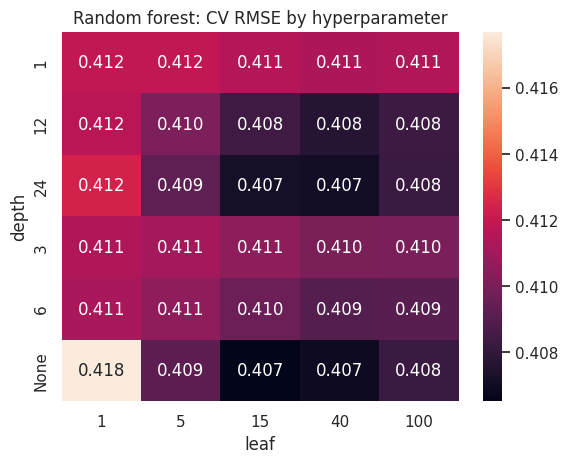

In [11]:
# 9. Compare training error with held-out CV error to diagnose fit.
# Use CV to choose the method BEFORE examining the final test set.
fit_rows = [{"Model": "Mean baseline", "Train RMSE": rmse(y_fit, dummy.predict(dummy_X)),
             "CV RMSE": dummy_cv.mean(), "CV fold SD": dummy_cv.std(ddof=1)}]
for name, search in searches.items():
    i = search.best_index_
    r = search.cv_results_
    fit_rows.append({"Model": name, "Train RMSE": -r["mean_train_score"][i],
                     "CV RMSE": -r["mean_test_score"][i],
                     "CV fold SD": r["std_test_score"][i]})
fit_table = pd.DataFrame(fit_rows).set_index("Model")
fit_table["CV minus train"] = fit_table["CV RMSE"] - fit_table["Train RMSE"]
display(fit_table.round(4))
fit_table[["Train RMSE", "CV RMSE"]].plot.bar(figsize=(9, 4), ylabel="RMSE (rating points)", rot=0)
plt.title("Fit diagnosis: training versus cross-validation")
plt.show()

# Large train/CV gap: evidence of overfitting.
# Both errors near baseline: weak predictive signal OR underfitting;
# the scores alone cannot distinguish these explanations.
# Similar, low errors that improve on baseline: evidence of a useful fit.
# CV scores after tuning are somewhat optimistic; the final test is separate.
chosen_name = min(searches, key=lambda name: -searches[name].best_score_)
chosen_model = searches[chosen_name].best_estimator_
cv_gain = 1 - (-searches[chosen_name].best_score_) / dummy_cv.mean()
print("Regression method selected by CV:", chosen_name)
print("Relative CV RMSE improvement over baseline:", f"{cv_gain:.1%}")
print("A small gain is a valid finding; do not describe it as strong prediction.")

# Heatmaps reveal whether performance is stable across settings or very sensitive.
for name, search in searches.items():
    r = pd.DataFrame(search.cv_results_)
    r["depth"] = r["params"].map(lambda p: str(p["model__max_depth"]))
    r["leaf"] = r["params"].map(lambda p: p["model__min_samples_leaf"])
    r["RMSE"] = -r["mean_test_score"]
    sns.heatmap(r.pivot(index="depth", columns="leaf", values="RMSE"), annot=True, fmt=".3f")
    plt.title(name + ": CV RMSE by hyperparameter")
    plt.show()


Sanity-check examples: read ingredients and open recipe URLs if useful.


,name,ingredients,actual,predicted,absolute_error,total_ratings,url
6809,Tortellini Alfredo with Grilled Chicken Breasts,"2 large skinless, boneless chicken breasts, 2 ...",4.3,4.705927,0.405927,4.0,https://www.allrecipes.com/recipe/276733/torte...
4142,Teriyaki and Pineapple Chicken,"2 tablespoons vegetable oil, 1 pound skinless,...",4.4,4.378781,0.021219,325.0,https://www.allrecipes.com/recipe/62124/teriya...
10327,Teriyaki Chicken with Mushrooms and Broccoli,"½ cup soy sauce, ½ cup rice vinegar, 3 tablesp...",4.0,4.447308,0.447308,22.0,https://www.allrecipes.com/recipe/267813/teriy...
10321,Easy Tex-Mex Chicken Tacos,"4 cups water, 1 (16 ounce) package yellow rice...",4.3,4.526682,0.226682,3.0,https://www.allrecipes.com/recipe/242344/easy-...
4670,Low-Fat Chicken Pot Pie,"3 bone-in chicken breast halves, skin removed,...",4.5,4.432334,0.067666,168.0,https://www.allrecipes.com/recipe/12620/low-fa...
7768,Best Homemade Chicken Pot Pie,"6 tablespoons butter, 1 cup finely chopped oni...",4.9,4.686383,0.213617,33.0,https://www.allrecipes.com/recipe/8343156/best...


Largest misses:


,name,ingredients,actual,predicted,absolute_error,total_ratings,url
8379,Air Fryer Samosas,"12 ounces yukon gold potatoes, peeled and cut ...",1.0,4.581323,3.581323,1.0,https://www.allrecipes.com/air-fryer-samosas-r...
7327,Mango and White Chocolate Mousse Cake,"3 ounces white chocolate, 3 tablespoons heavy ...",1.0,4.539000,3.539000,1.0,https://www.allrecipes.com/recipe/257190/mango...
5873,Pumpkin Pie with Truvia® Natural Sweetener,"pastry for a single-crust 9-inch pie, 1 (16 ou...",2.0,4.481167,2.481167,1.0,https://www.allrecipes.com/recipe/229475/pumpk...
11593,Coffee-Rubbed Steak,"1/4 cup finely ground coffee, 2 tablespoons da...",2.0,4.479761,2.479761,1.0,https://www.allrecipes.com/coffee-rubbed-steak...
7639,One-Pan Oven Mac and Cheese,"½ (8 ounce) package fontina cheese, ½ (8 ounce...",2.3,4.567587,2.267587,6.0,https://www.allrecipes.com/recipe/283949/one-p...
9092,Chocolate Cream Filled Cookies,"6 tablespoons butter, softened, ¼ cup white su...",2.3,4.396310,2.096310,3.0,https://www.allrecipes.com/recipe/168802/choco...
11136,Baked Banana Chips,"2 just-ripe bananas, sliced in 1/10-inch-thic...",2.7,4.674498,1.974498,14.0,https://www.allrecipes.com/recipe/261342/baked...
11006,Coconut Fudge,"2 cups white sugar, 1 (14 ounce) can sweetened...",2.5,4.472532,1.972532,6.0,https://www.allrecipes.com/recipe/256063/cocon...


Smallest misses:


,name,ingredients,actual,predicted,absolute_error,total_ratings,url
14146,South African Malvapoeding (Marshmallow Pudding),"½ cup milk, 2 tablespoons unsalted butter, 1 t...",4.6,4.599802,0.000198,40.0,https://www.allrecipes.com/recipe/58465/south-...
176,Homemade Mince Pie with Crumbly Topping,"2 1/4 cups all-purpose flour, divided, ½ cup u...",4.6,4.599653,0.000347,14.0,https://www.allrecipes.com/recipe/215756/homem...
7837,Mom's Favorite Baked Mac and Cheese,"2 tablespoons butter, ¼ cup finely chopped oni...",4.5,4.499363,0.000637,1.0,https://www.allrecipes.com/recipe/24321/moms-f...
485,Caramel-Pecan Pumpkin Pie,"1 (15 ounce) can pumpkin purée, ½ cup half-and...",4.5,4.500795,0.000795,73.0,https://www.allrecipes.com/recipe/130635/caram...
3205,Turkey-Stuffed Peppers,"2 large red bell peppers, tops and seeds remov...",4.6,4.600865,0.000865,16.0,https://www.allrecipes.com/recipe/233445/turke...
10996,Basic Brine for Smoking Meat,"4 cups water, ¼ cup packed brown sugar, ¼ cup ...",4.7,4.699135,0.000865,81.0,https://www.allrecipes.com/recipe/17945/basic-...
7424,Homemade Limoncello,"10 lemons, 1 liter vodka, 3 cups white sugar,...",4.5,4.500946,0.000946,195.0,https://www.allrecipes.com/recipe/32451/limonc...
1424,Easy Pesto,"¼ cup almonds, 3 cloves garlic, 1 ½ cups fresh...",4.5,4.501437,0.001437,382.0,https://www.allrecipes.com/recipe/41596/easy-p...


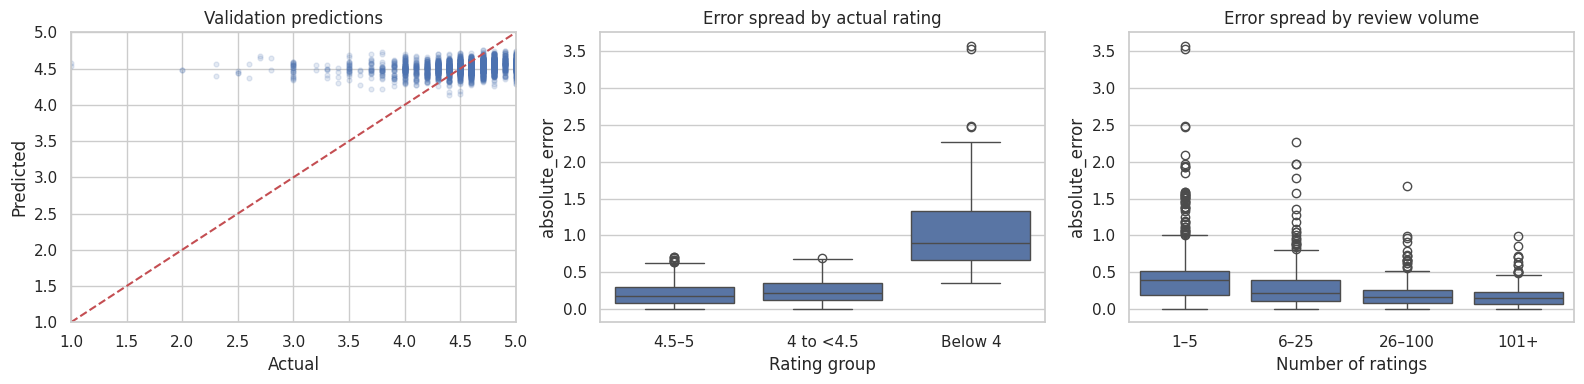

count      mean    median
rating_band review_group                           
4 to <4.5   1–5             122  0.398912  0.449692
            6–25            160  0.251867  0.220141
            26–100          157  0.206944  0.193832
            101+            142  0.180528  0.163579
4.5–5       1–5             382  0.302971  0.333438
            6–25            366  0.206740  0.188398
            26–100          390  0.160086  0.152390
            101+            457  0.153739  0.141346
Below 4     1–5              62  1.392351  1.347443
            6–25             58  0.857121  0.719890
            26–100           22  0.705509  0.655986
            101+             11  0.649527  0.637153

In [12]:
# 10. Diagnose validation errors BEFORE final testing.
# For regression, errors are continuous rather than simply right or wrong.
def error_frame(X_part, y_part, model):
    out = model_df.loc[X_part.index].copy()
    out["actual"] = y_part
    out["predicted"] = model.predict(X_part)
    out["residual"] = out["actual"] - out["predicted"]
    out["absolute_error"] = out["residual"].abs()
    out["review_group"] = pd.cut(out["total_ratings"], [0, 5, 25, 100, np.inf],
                                 labels=["1–5", "6–25", "26–100", "101+"])
    out["rating_band"] = pd.cut(out["actual"], [0, 4, 4.5, 5],
                                right=False, labels=["Below 4", "4 to <4.5", "4.5 to <5"])
    # Include exactly 5.0 in the high group.
    out["rating_band"] = np.where(out["actual"] < 4, "Below 4",
                          np.where(out["actual"] < 4.5, "4 to <4.5", "4.5–5"))
    return out

val_errors = error_frame(X_val, y_val, chosen_model)
show_cols = [c for c in ["name", "ingredients", "actual", "predicted",
                        "absolute_error", "total_ratings", "url"] if c in val_errors]
# Inspect familiar examples chosen by name, not by their errors.
if "name" in val_errors:
    familiar = val_errors["name"].str.contains("brownie|pancake|chicken", case=False, na=False)
    print("Sanity-check examples: read ingredients and open recipe URLs if useful.")
    display(val_errors.loc[familiar, show_cols].head(6))
print("Largest misses:")
display(val_errors.nlargest(8, "absolute_error")[show_cols])
print("Smallest misses:")
display(val_errors.nsmallest(8, "absolute_error")[show_cols])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(val_errors["actual"], val_errors["predicted"], alpha=.15, s=12)
axes[0].plot([1, 5], [1, 5], "r--")
axes[0].set(xlabel="Actual", ylabel="Predicted", xlim=(1, 5), ylim=(1, 5), title="Validation predictions")
sns.boxplot(data=val_errors, x="rating_band", y="absolute_error", ax=axes[1])
axes[1].set(title="Error spread by actual rating", xlabel="Rating group")
sns.boxplot(data=val_errors, x="review_group", y="absolute_error", ax=axes[2])
axes[2].set(title="Error spread by review volume", xlabel="Number of ratings")
plt.tight_layout()
plt.show()
display(val_errors.groupby(["rating_band", "review_group"], observed=True)["absolute_error"].agg(["count", "mean", "median"]))

# Report small group sizes. Do not call a pattern reliable from just a few cases.
# If sparse-review recipes are harder, flag uncertainty for that group.
# If low ratings are harder, discuss imbalance and regression toward the mean.
# Ingredient-only inputs cannot describe cooking technique, execution, or taste.
# Adding those features would require another training/validation cycle.


Chosen model threshold: 4.45
Policy selected using validation: Model threshold


,Validation value per recipe ($)
Model threshold,-0.093602
Promote everyone,-0.206097
Promote no one,-0.684843


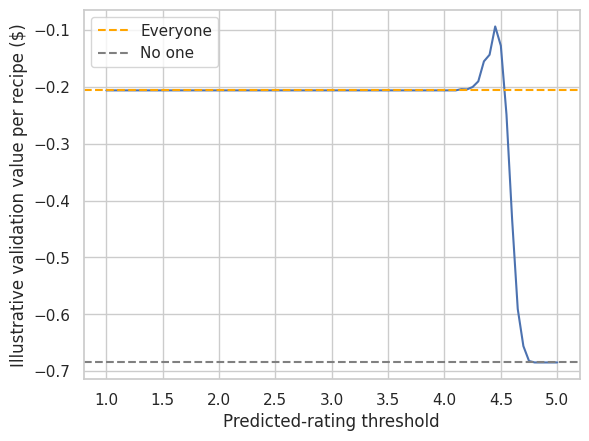

In [13]:
# 11. Turn predictions into an illustrative recommendation decision.
# Business assumption: promote a recipe if it is likely to score at least 4.5.
# These dollar values are SCENARIO ASSUMPTIONS, not measured revenue.
# Promote a good recipe: +$2; promote a lower-rated recipe: -$5.
# Skip a good recipe: -$1 opportunity cost; skip a lower-rated recipe: $0.
GOOD_RATING = 4.5
VALUE_TP, VALUE_FP, VALUE_FN, VALUE_TN = 2.0, -5.0, -1.0, 0.0

def policy_value(actual, promote):
    good = np.asarray(actual) >= GOOD_RATING
    promote = np.asarray(promote, dtype=bool)
    return np.where(promote & good, VALUE_TP,
           np.where(promote & ~good, VALUE_FP,
           np.where(~promote & good, VALUE_FN, VALUE_TN)))

# Tune the prediction threshold on validation data, NEVER on test data.
# Include thresholds that promote everyone or no one.
thresholds = np.r_[-np.inf, np.linspace(1, 5, 81), np.inf]
val_pred = chosen_model.predict(X_val)
value_curve = np.array([policy_value(y_val, val_pred >= t).mean() for t in thresholds])
# Resolve ties toward a higher threshold (fewer promotions).
best_index = np.flatnonzero(np.isclose(value_curve, value_curve.max()))[-1]
chosen_threshold = thresholds[best_index]
val_policies = {"Model threshold": value_curve[best_index],
                "Promote everyone": policy_value(y_val, np.ones(len(y_val), bool)).mean(),
                "Promote no one": policy_value(y_val, np.zeros(len(y_val), bool)).mean()}
# Prefer a simple policy when it ties with the model.
policy_order = ["Promote no one", "Promote everyone", "Model threshold"]
selected_policy = max(policy_order, key=lambda name: val_policies[name])
print("Chosen model threshold:", chosen_threshold)
print("Policy selected using validation:", selected_policy)
display(pd.Series(val_policies, name="Validation value per recipe ($)"))
finite = np.isfinite(thresholds)
plt.plot(thresholds[finite], value_curve[finite])
plt.axhline(val_policies["Promote everyone"], color="orange", linestyle="--", label="Everyone")
plt.axhline(val_policies["Promote no one"], color="gray", linestyle="--", label="No one")
plt.xlabel("Predicted-rating threshold")
plt.ylabel("Illustrative validation value per recipe ($)")
plt.legend()
plt.show()
# Keep the model fitted on X_fit: refitting would change its predictions and
# the relationship between the selected threshold and validation performance.


In [14]:
# 12. Try classification as a complementary question, especially if RMSE gain is weak.
# Fixed bins avoid using test outcomes to decide class boundaries:
# low: rating < 4; medium: 4 <= rating < 4.5; high: rating >= 4.5.
# Balanced accuracy gives each class equal weight despite unequal frequencies.
# Any constant-class baseline has balanced accuracy 1/3 when all classes exist.
# We still show a most-frequent dummy, plus ordinary accuracy in the report.
def rating_class(values):
    a = np.asarray(values)
    return np.where(a < 4, "low", np.where(a < 4.5, "medium", "high"))

y_fit_class = rating_class(y_fit)
class_counts = pd.Series(y_fit_class).value_counts()
display(class_counts)
class_searches = {}
if len(class_counts) < 3 or class_counts.min() < 3:
    print("Too few cases in at least one class for reliable 3-fold classification.")
else:
    class_cv = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_fit, y_fit_class))
    class_dummy = DummyClassifier(strategy="most_frequent").fit(dummy_X, y_fit_class)
    class_dummy_cv = cross_val_score(class_dummy, dummy_X, y_fit_class,
                                    cv=class_cv, scoring="balanced_accuracy")
    for name, model in {
        "Classification tree": DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
        "Classification forest": RandomForestClassifier(n_estimators=120, max_features=0.5,
                    class_weight="balanced", random_state=SEED, n_jobs=1)
    }.items():
        class_searches[name], _ = tune(model, X_fit, y_fit_class, class_cv, "balanced_accuracy")
    class_choice = max(class_searches, key=lambda name: class_searches[name].best_score_)
    print("Classifier selected using CV:", class_choice)
    print("Interpret regression and classification separately; their scores use different scales.")


,count
high,6311
medium,2440
low,564


Fitting 3 folds for each of 30 candidates, totalling 90 fits
DecisionTreeClassifier {'model__max_depth': 6, 'model__min_samples_leaf': 1} CV score: 0.3842 minutes: 1.7
Fitting 3 folds for each of 30 candidates, totalling 90 fits
RandomForestClassifier {'model__max_depth': 12, 'model__min_samples_leaf': 40} CV score: 0.423 minutes: 12.4
Classifier selected using CV: Classification forest
Interpret regression and classification separately; their scores use different scales.


In [15]:
# 13. FINAL evaluation: run after locking models, thresholds, and class bins.
# Do not revise them in response to these results and reuse this as a fresh test.
test_predictions = {"Mean baseline": dummy.predict(np.zeros((len(X_test), 1)))}
train_predictions = {"Mean baseline": dummy.predict(dummy_X)}
for name, search in searches.items():
    test_predictions[name] = search.best_estimator_.predict(X_test)
    train_predictions[name] = search.best_estimator_.predict(X_fit)

rows = []
for name, pred in test_predictions.items():
    rows.append({"Model": name, "Train RMSE": rmse(y_fit, train_predictions[name]),
                 "CV RMSE": fit_table.loc[name, "CV RMSE"],
                 "Test RMSE": rmse(y_test, pred),
                 "Test MAE": mean_absolute_error(y_test, pred),
                 "Test R2": r2_score(y_test, pred)})
results = pd.DataFrame(rows).set_index("Model")
results["Test RMSE improvement (%)"] = 100 * (1 - results["Test RMSE"] / results.loc["Mean baseline", "Test RMSE"])
display(results.round(4))
print("The preselected method was:", chosen_name)
print("Positive residuals mean the model underpredicted the rating.")
print("MAE is the average absolute miss; R² can be negative when prediction is poor.")

# Paired bootstrap estimates uncertainty in the selected model's RMSE gain.
# This holds the fitted models fixed; it does not capture training-set variation.
rng = np.random.default_rng(SEED)
actual = y_test.to_numpy()
base_pred = test_predictions["Mean baseline"]
pred = test_predictions[chosen_name]
gains = []
for _ in range(1000):
    idx = rng.integers(0, len(actual), len(actual))
    gains.append(rmse(actual[idx], base_pred[idx]) - rmse(actual[idx], pred[idx]))
lo, hi = np.quantile(gains, [.025, .975])
print(f"Approximate 95% interval for baseline RMSE minus model RMSE: [{lo:.4f}, {hi:.4f}]")
print("If the interval includes zero, improvement is uncertain on this test sample.")

# Evaluate the frozen decision threshold and both simple policies.
actions = {"Model threshold": pred >= chosen_threshold,
           "Promote everyone": np.ones(len(y_test), bool),
           "Promote no one": np.zeros(len(y_test), bool)}
policy_rows = []
for name, promote in actions.items():
    good = actual >= GOOD_RATING
    values = policy_value(actual, promote)
    policy_rows.append({"Policy": name, "Promoted": int(promote.sum()),
                       "Good promoted": int((promote & good).sum()),
                       "Poor promoted": int((promote & ~good).sum()),
                       "Good skipped": int((~promote & good).sum()),
                       "Value per recipe ($)": values.mean(), "Total value ($)": values.sum()})
policy_results = pd.DataFrame(policy_rows).set_index("Policy")
display(policy_results.round(3))
print("Policy selected before testing:", selected_policy)
print("These values describe the assumed scenario, not realized financial returns.")


,Train RMSE,CV RMSE,Test RMSE,Test MAE,Test R2,Test RMSE improvement (%)
Model,,,,,,
Mean baseline,0.4133,0.4131,0.4139,0.2829,-0.0000,0.0000
Regression tree,0.4088,0.4107,0.4128,0.2807,0.0053,0.2657
Random forest,0.3713,0.4065,0.4079,0.2741,0.0288,1.4501


The preselected method was: Random forest
Positive residuals mean the model underpredicted the rating.
MAE is the average absolute miss; R² can be negative when prediction is poor.
Approximate 95% interval for baseline RMSE minus model RMSE: [0.0030, 0.0089]
If the interval includes zero, improvement is uncertain on this test sample.


,Promoted,Good promoted,Poor promoted,Good skipped,Value per recipe ($),Total value ($)
Policy,,,,,,
Model threshold,2317,1638,679,328,-0.154,-447.0
Promote everyone,2911,1966,945,0,-0.272,-793.0
Promote no one,0,0,0,1966,-0.675,-1966.0


Policy selected before testing: Model threshold
These values describe the assumed scenario, not realized financial returns.


,Train balanced accuracy,CV balanced accuracy,Test balanced accuracy
Model,,,
Most-frequent baseline,0.3333,0.3333,0.3333
Classification tree,0.4507,0.3842,0.3862
Classification forest,0.5687,0.4230,0.4143


              precision    recall  f1-score   support

         low       0.10      0.38      0.16       175
      medium       0.32      0.30      0.31       770
        high       0.73      0.56      0.64      1966

    accuracy                           0.48      2911
   macro avg       0.38      0.41      0.37      2911
weighted avg       0.58      0.48      0.52      2911



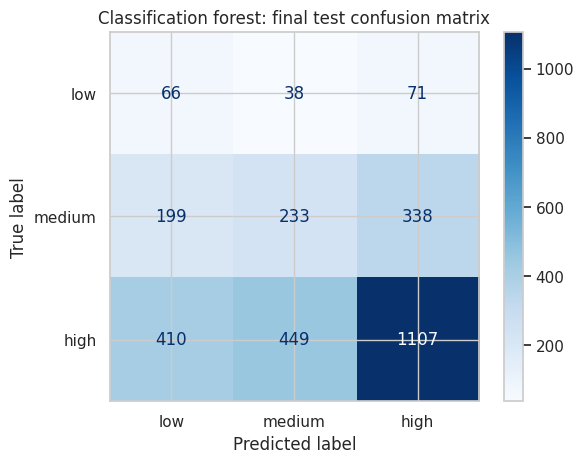

If a class is absent in the test set, balanced accuracy is not comparable to the three-class CV score.
Misclassified examples:


,name,ingredients,total_ratings,actual_class,predicted_class
14283,Lancaster Lefsa (Old World Recipe),"3 cups mashed potatoes, ¼ cup shortening, 3 ta...",2.0,high,low
2677,Bacon Dill Pickle Pizzas,"2 naan breads, 2 teaspoons olive oil, or as ne...",1.0,low,medium
4295,Delicious Egg Salad,"8 large eggs, ½ cup mayonnaise, ¼ cup chopped ...",2.0,high,medium
11295,Indian Rice Pilaf,"¼ cup water, 1 (14.5 ounce) can chicken broth,...",33.0,medium,low
3887,Pumpkin Cheese Ball,"2 (8-ounce) packages cream cheese, softened, 1...",1.0,high,medium
9270,Air Fryer Pecan Crusted Trout,"2/3 cup finely chopped pecans, 1 teaspoon drie...",1.0,high,low
13912,How to Make Beef Satay,"¼ cup packed brown sugar, ¼ cup fish sauce, 4 ...",85.0,high,medium
3248,Brown Bears,"1 cup white sugar, ¼ cup ground cinnamon, ½ cu...",23.0,high,low


Correct examples:


,name,ingredients,total_ratings,actual_class,predicted_class
2021,Healthier Monkey Bread I,"⅓ cup white sugar, 2 teaspoons ground cinnamon...",4.0,high,high
11438,Pineapple Crisp,"2 (20 ounce) cans crushed pineapple, well drai...",185.0,high,high
1984,Hot Artichoke Dip with Green Chiles,"½ (16 ounce) jar creamy salad dressing, 1 clov...",10.0,medium,medium
7110,Quick Thousand Island Dressing,"1 cup mayonnaise, ¼ cup ketchup, ¼ cup sweet p...",32.0,high,high
8629,Watermelon Pink Lemonade,"1 cup water, 2 tablespoons lemon juice, 4 teas...",8.0,high,high
3488,Jalapeño Cream Cheese Chicken Enchiladas,"3 skinless, boneless chicken breasts, 3 ½ teas...",567.0,high,high
2858,Coconut and Marzipan Macaroons,"5 large egg whites, 18 ounces marzipan, 2 cups...",1.0,low,low
2167,Instant Pot Yankee Pot Roast,"¼ cup all-purpose flour, 1 tablespoon kosher s...",9.0,high,high


In [16]:
# 14. Final classification comparison on the SAME recipe test split.
if class_searches:
    y_test_class = rating_class(y_test)
    class_rows = []
    cp = class_dummy.predict(np.zeros((len(X_test), 1)))
    class_rows.append({"Model": "Most-frequent baseline", "Train balanced accuracy":
        balanced_accuracy_score(y_fit_class, class_dummy.predict(dummy_X)),
        "CV balanced accuracy": class_dummy_cv.mean(),
        "Test balanced accuracy": balanced_accuracy_score(y_test_class, cp)})
    for name, search in class_searches.items():
        p = search.predict(X_test)
        class_rows.append({"Model": name,
            "Train balanced accuracy": balanced_accuracy_score(y_fit_class, search.predict(X_fit)),
            "CV balanced accuracy": search.best_score_,
            "Test balanced accuracy": balanced_accuracy_score(y_test_class, p)})
    display(pd.DataFrame(class_rows).set_index("Model").round(4))
    class_pred = class_searches[class_choice].predict(X_test)
    print(classification_report(y_test_class, class_pred, labels=["low", "medium", "high"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test_class, class_pred,
                    labels=["low", "medium", "high"], cmap="Blues")
    plt.title(class_choice + ": final test confusion matrix")
    plt.show()
    print("If a class is absent in the test set, balanced accuracy is not comparable to the three-class CV score.")
    # Compare specific misses with correct classifications, keeping metadata visible.
    class_errors = model_df.loc[X_test.index].copy()
    class_errors["actual_class"] = y_test_class
    class_errors["predicted_class"] = class_pred
    class_errors["correct"] = class_pred == y_test_class
    columns = [c for c in ["name", "ingredients", "total_ratings", "actual_class", "predicted_class"] if c in class_errors]
    print("Misclassified examples:")
    display(class_errors.loc[~class_errors["correct"], columns].head(8))
    print("Correct examples:")
    display(class_errors.loc[class_errors["correct"], columns].head(8))


,name,ingredients,actual,predicted,absolute_error,total_ratings,url
10127,Artichoke Parmesan Soup,"1 tablespoon olive oil, 1 onion, chopped, 2 (1...",1.0,4.553238,3.553238,1.0,https://www.allrecipes.com/artichoke-parmesan-...
13105,CAMPBELL'S® Thai Tacos,"1 pound lean ground pork, 1 tablespoon minced ...",1.0,4.519147,3.519147,1.0,https://www.allrecipes.com/recipe/270100/campb...
10982,Chocolate-Gingerbread Cookies,"7 ounces semisweet chocolate, 1 ½ cups all-pur...",1.0,4.490422,3.490422,1.0,https://www.allrecipes.com/recipe/277712/choco...
2858,Coconut and Marzipan Macaroons,"5 large egg whites, 18 ounces marzipan, 2 cups...",1.0,4.486870,3.486870,1.0,https://www.allrecipes.com/recipe/282194/cocon...
12263,Easy Pot Pie with Biscuits,1 (12.5 fl oz) can chunky shredded chicken (su...,1.0,4.429369,3.429369,1.0,https://www.allrecipes.com/recipe/276222/easy-...
2310,Gluten Free Lemon Coconut Poppy Seed Bars,"½ cup coconut flour, ¼ cup almond flour, 2 tab...",2.0,4.623534,2.623534,1.0,https://www.allrecipes.com/recipe/241047/glute...
3721,Dirty Soda Cookies,"1 (15 ounce) box devil's food cake mix, 6 flui...",2.0,4.558987,2.558987,2.0,https://www.allrecipes.com/dirty-soda-cookies-...
2662,'Nuff Said Maple Bacon Fudge,"⅓ pound smoked maple bacon, cut into 1/4-inch ...",2.0,4.519702,2.519702,4.0,https://www.allrecipes.com/recipe/228780/nuff-...
10868,Easy Crab Cakes,"1 ¾ pounds cooked crabmeat, 2 large eggs, 1 ½ ...",2.0,4.496786,2.496786,1.0,https://www.allrecipes.com/recipe/281379/easy-...
8441,Fruit-Oat Bars,"cooking spray, ⅔ cup packed brown sugar, ½ cup...",2.0,4.496473,2.496473,1.0,https://www.allrecipes.com/recipe/274535/fruit...


,count,mean,median
review_group,,,
1–5,739,0.458221,0.384775
6–25,670,0.275155,0.233587
26–100,681,0.204708,0.171734
101+,821,0.165167,0.151341


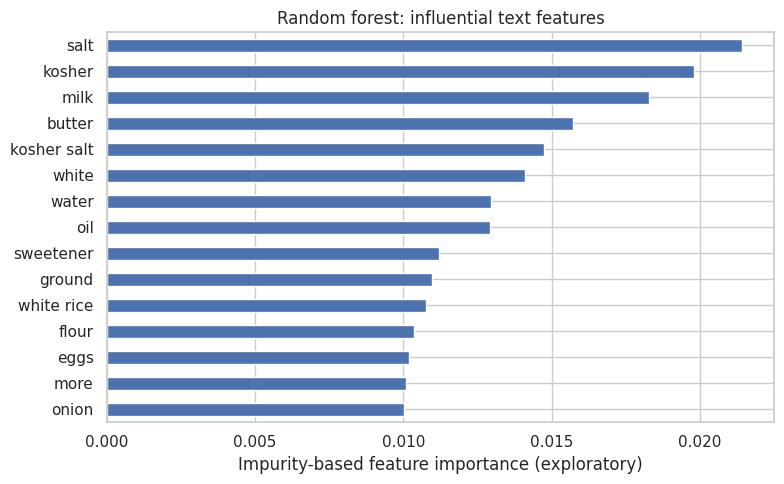

Saved result tables to the Colab Files panel.


In [17]:
# 15. Final error audit and export tables for your presentation.
# This is reporting, not another tuning step.
test_errors = error_frame(X_test, y_test, chosen_model)
display(test_errors.nlargest(10, "absolute_error")[show_cols])
display(test_errors.groupby("review_group", observed=True)["absolute_error"].agg(["count", "mean", "median"]))

# Extract the most-used words/phrases. Importance is NOT causation and has no sign.
# Impurity importance can be unstable with correlated words; treat as exploratory.
vocabulary = chosen_model.named_steps["ingredients"].get_feature_names_out()
importance = pd.Series(chosen_model.named_steps["model"].feature_importances_, index=vocabulary)
importance.nlargest(15).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel("Impurity-based feature importance (exploratory)")
plt.title(chosen_name + ": influential text features")
plt.tight_layout()
plt.show()

results.to_csv("regression_comparison.csv")
policy_results.to_csv("decision_policy_comparison.csv")
test_errors.to_csv("recipe_test_predictions.csv", index=False)
for name, search in searches.items():
    pd.DataFrame(search.cv_results_).to_csv(name.lower().replace(" ", "_") + "_tuning.csv", index=False)
print("Saved result tables to the Colab Files panel.")


## What to write after running the notebook

- **Metric:** “We used RMSE because ratings are numeric and larger prediction errors should receive greater weight. An RMSE of 0.40 would mean a root-mean-square error of 0.40 rating points.” Use your actual score, not this example.
- **Baseline:** Report the mean baseline beside both regressors, including the percentage reduction in test RMSE. If the gain is small, say ingredients alone provide little useful predictive information.
- **Tuning:** Report the final searched ranges, best depth/leaf size, three-fold CV, fixed forest size of 120, and vocabulary settings. The initial search tests 30 combinations per method; boundary expansions may add more. Computation time is printed.
- **Fit:** A large training/CV gap supports overfitting. Similar but baseline-level errors can mean underfitting or insufficient ingredient signal. Do not label a model “fitting well” just because the gap is small.
- **Errors:** Name concrete recipes, compare easy and hard cases, and show subgroup sample sizes and spread. Explain whether review volume, unusual ingredients, or low ratings are associated with misses. These are associations, not causal explanations.
- **Action:** If low-review recipes are unreliable, flag those predictions for human review. If ingredients omit the apparent explanation, collect preparation or technique features for a future model. Do not quietly add review counts as predictors to an ingredients-only study. If subgroup evidence is sparse, say so.
- **Classification:** Explain the fixed low/medium/high bins and compare both classifiers with the dummy using balanced accuracy. Better class prediction with poor numeric prediction suggests coarse signal, not precise rating knowledge. If both fail, reject the premise that ingredient text alone is enough.
- **Deployment:** Name the method chosen by CV, then discuss whether final RMSE gain and the assumed policy value justify using it. Prefer the baseline/simple policy if the gains are negligible or uncertain. A random forest need not win. Final test evidence may support declining deployment, but should not initiate another tuning cycle on the same test set.
- **Limitations:** The split tests new recipe records from the same dataset, not future time periods or new websites. Exact duplicates are removed, but near-duplicate recipes may remain. Observed ratings are noisy, text features are approximate, and scenario dollar values need real business validation.

### References
- [DummyRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html)
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [CountVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
- [Course project](https://github.com/elhamod/BA305_Fall_2026/tree/main/Project) — workflow based on the assignment text pasted into the conversation.